**Predicting Customer Churn Using Neural Network**





In this dataset I am using neural netwokmultilayer for detecting the output data which is customers data and we need to prdict either customers will saty or churn.

This project uses a Multilayer Perceptron (MLP) neural network to predict whether a customer will stay with a company (class 0) or leave the company (class 1). The goal is to identify customers at risk of churn and help businesses develop customer-retention strategies.

Data Preprocessing and Feature Engineering
Applied feature scaling to numerical variables.
Used one-hot encoding to transform categorical variables into numerical features.
Split the dataset into training and testing sets.
Examined the target distribution and identified class imbalance, with more customers staying than churning.

**Importing the important libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Loading the data**

In [ ]:
data=pd.read_csv('/content/Churn Modeling.csv')
data

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [ ]:
data.head(2)
data.tail(2)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [ ]:
data.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [ ]:
#TO check null values
data.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


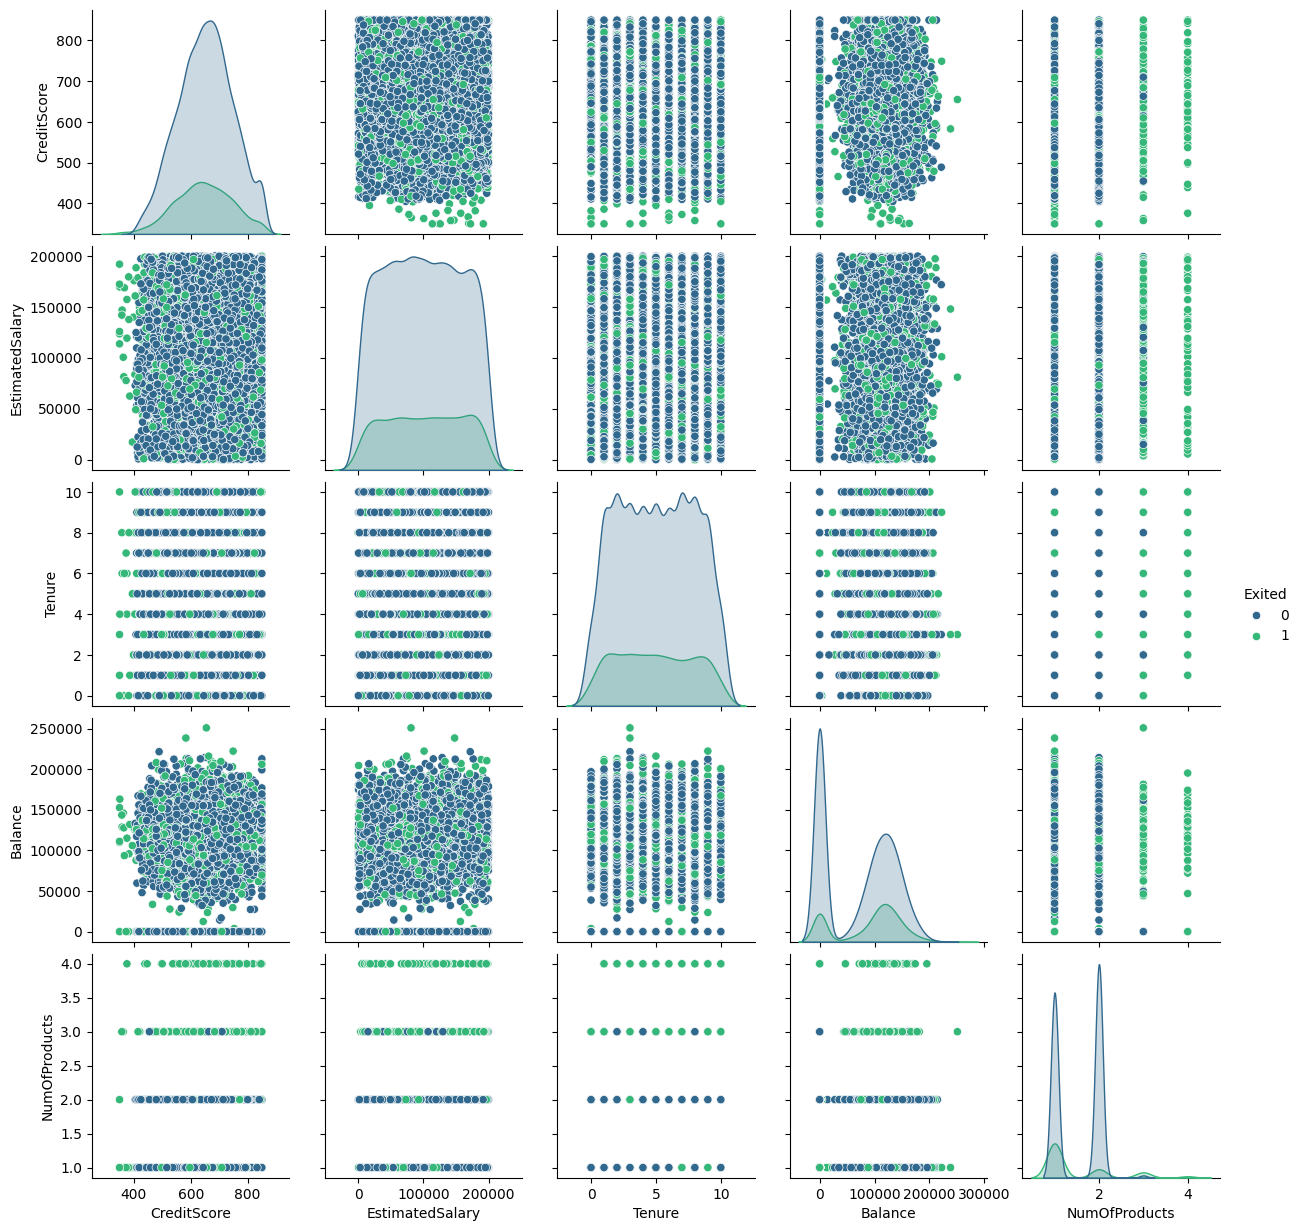

In [ ]:
# pair plot
sns.pairplot(
    data[["CreditScore", "EstimatedSalary", "Tenure", "Balance","NumOfProducts","Exited"]],
    hue="Exited",
 palette="viridis"
)
plt.show()

In [ ]:
# columns
data.columns


Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

**Dropping the columns**

In [ ]:
#dropping columns
df=data.drop(['RowNumber','CustomerId','Surname'],axis=1)
df.head(1)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.0,1,1,1,101348.88,1


In [ ]:
#value counts
df.Geography.value_counts()
print(df.Geography.value_counts())
df.Gender.value_counts()
print(df.Gender.value_counts())

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64
Gender
Male      5457
Female    4543
Name: count, dtype: int64


**Seperating the features and output columns**

In [ ]:

X=df.drop(['Exited'],axis=1)
y=df['Exited']

In [ ]:
cat_col=[col for col in X.columns if df[col].dtype=='object']
print(cat_col)
Numerical_col=[col for col in X.columns if df[col].dtype!='object']
print(Numerical_col)


['Geography', 'Gender']
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


**Columns Transformer**

In [ ]:

from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), Numerical_col),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_col)
])




In [ ]:
X_transform=preprocessor.fit_transform(X)
X_transform

array([[-0.32622142,  0.29351742, -1.04175968, ...,  0.        ,
         0.        ,  0.        ],
       [-0.44003595,  0.19816383, -1.38753759, ...,  0.        ,
         1.        ,  0.        ],
       [-1.53679418,  0.29351742,  1.03290776, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 0.60498839, -0.27860412,  0.68712986, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.25683526,  0.29351742, -0.69598177, ...,  1.        ,
         0.        ,  1.        ],
       [ 1.46377078, -1.04143285, -0.35020386, ...,  0.        ,
         0.        ,  0.        ]])

**Splitting the data for train and test**

In [ ]:

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


In [ ]:

X_train_transform=preprocessor.fit_transform(X_train)
X_test_transform=preprocessor.transform(X_test)
print(X_train_transform.shape)
print(X_test_transform.shape)
print(y_train.shape)
print(y_test.shape)

(8000, 11)
(2000, 11)
(8000,)
(2000,)


**building the model**

In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
model = keras.Sequential([
    keras.Input(shape=(X_train_transform.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])


In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

**Compling the model**

In [ ]:

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

**Training the model**

In [ ]:


history = model.fit(
    X_train_transform,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8027 - loss: 0.4622 - val_accuracy: 0.8400 - val_loss: 0.4006
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8422 - loss: 0.3838 - val_accuracy: 0.8512 - val_loss: 0.3635
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8562 - loss: 0.3540 - val_accuracy: 0.8562 - val_loss: 0.3503
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8597 - loss: 0.3445 - val_accuracy: 0.8531 - val_loss: 0.3470
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8603 - loss: 0.3390 - val_accuracy: 0.8519 - val_loss: 0.3454
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8623 - loss: 0.3358 - val_accuracy: 0.8569 - val_loss: 0.3450
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8614 - loss: 0.3329 - val_accuracy: 0.8587 - val_loss: 0.3501
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8628 - loss: 0.3306 - val_accuracy: 0

In [ ]:

test_loss, test_accuracy = model.evaluate( X_test_transform, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8610 - loss: 0.3505
Test Loss: 0.3504860997200012
Test Accuracy: 0.8610000014305115


**Predicting the model**

**y_pred_probality**

In [ ]:

y_pred_prob=model.predict(X_test_transform)
y_pred_prob

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


array([[0.00388112],
       [0.00650987],
       [0.07568409],
       ...,
       [0.7529579 ],
       [0.16801411],
       [0.18277392]], dtype=float32)

In [ ]:

y_pred = (y_pred_prob > 0.5).astype(int)
y_pred

array([[0],
       [0],
       [0],
       ...,
       [1],
       [0],
       [0]])

**To Check the confusion matrix**

In [ ]:

from sklearn.metrics import confusion_matrix,classification_report
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))





[[1520   87]
 [ 199  194]]
              precision    recall  f1-score   support

           0       0.88      0.95      0.91      1607
           1       0.69      0.49      0.58       393

    accuracy                           0.86      2000
   macro avg       0.79      0.72      0.74      2000
weighted avg       0.85      0.86      0.85      2000



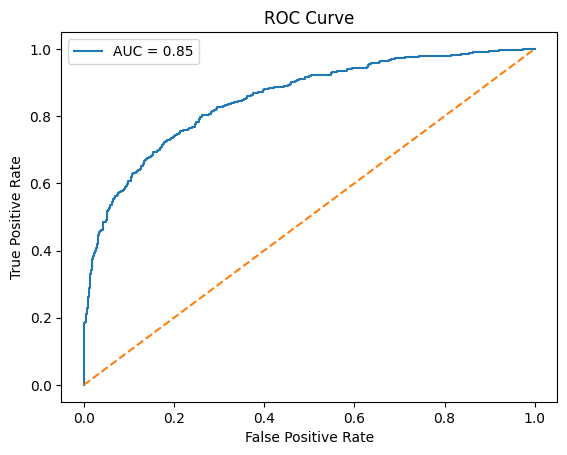

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

auc = roc_auc_score(y_test, y_pred_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


**Model Evaluation**

The multilayer neural network achieved 86% accuracy, with a macro F1-score of 0.74 and a weighted F1-score of 0.85 on 2,000 test samples. For the churn class, precision was 69%, recall was 49%, and the F1-score was 58%. The confusion matrix shows that the model correctly identified 194 churners but missed 199 actual churners. Due to class imbalance, the model performs better at identifying customers who stay than those who leave. Future improvements will focus on increasing churn recall through threshold tuning and class-weighting techniques.